In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset
import ast 
from adjustText import adjust_text

dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x : ast.literal_eval(x) if pd.notna(x) else x)
df_anal = df[df['job_title_short'] == 'Data Analyst']
df_skills = df_anal.explode('job_skills')

In [2]:
skill_stats = df_skills.groupby('job_skills').agg(
    skill_count = ('job_skills', 'count'),
    median_salary = ('salary_year_avg', 'median')
)

In [3]:
skill_stats = skill_stats.sort_values(by='skill_count', ascending=False).head(20)

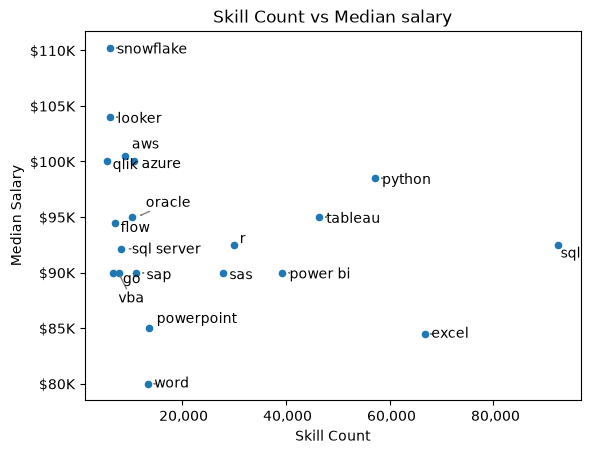

In [ ]:


skill_stats.plot(kind='scatter', x='skill_count', y='median_salary')
plt.xlabel('Skill Count')
plt.ylabel('Median Salary')
texts=[]

for i, skill in enumerate(skill_stats.index):
    x = skill_stats['skill_count'].iloc[i] + 1000
    y = skill_stats['median_salary'].iloc[i]
    texts.append(plt.text(x, y, skill, va='center'))
    plt.title('Skill Count vs Median salary')
    
ax = plt.gca()
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, pos : f'${int(y/1000)}K')) 
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos : f'{int(x): ,}'))   
# : , inside the f-string formats the integer with a thousands separator (commas).
adjust_text(texts, arrowprops=dict(arrowstyle='->', color='gray', lw=1))
plt.show()